<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate Synthetic Credit Data
print("Generating synthetic credit dataset...")
n_samples = 1000

data = {
    'Age': np.random.randint(18, 70, size=n_samples),
    'Annual_Income': np.random.normal(55000, 25000, size=n_samples).clip(10000, 200000),
    'Num_Bank_Accounts': np.random.randint(1, 10, size=n_samples),
    'Num_Credit_Cards': np.random.randint(1, 12, size=n_samples),
    'Interest_Rate': np.random.uniform(1, 35, size=n_samples),
    'Num_of_Loan': np.random.randint(0, 10, size=n_samples),
    'Delay_from_due_date': np.random.randint(0, 40, size=n_samples),
    'Num_of_Delayed_Payment': np.random.randint(0, 25, size=n_samples),
    'Outstanding_Debt': np.random.uniform(100, 5000, size=n_samples),
    'Credit_History_Age_Months': np.random.randint(6, 400, size=n_samples)
}

df = pd.DataFrame(data)

# Define simple rules to assign target 'Credit_Score' labels based on generated attributes
score_index = (
    (df['Annual_Income'] / 10000)
    - (df['Interest_Rate'] * 0.5)
    - (df['Delay_from_due_date'] * 0.8)
    - (df['Outstanding_Debt'] / 500)
    + (df['Credit_History_Age_Months'] / 30)
)

# Assign classes based on quantile thresholds
threshold_low = np.percentile(score_index, 33)
threshold_high = np.percentile(score_index, 66)

def label_score(val):
    if val < threshold_low:
        return 'Poor'
    elif val < threshold_high:
        return 'Standard'
    else:
        return 'Good'

df['Credit_Score'] = score_index.map(label_score)

print(f"Dataset generated successfully with {df.shape[0]} rows and {df.shape[1]} columns.")
display(df.head())


Generating synthetic credit dataset...
Dataset generated successfully with 1000 rows and 11 columns.


,Age,Annual_Income,Num_Bank_Accounts,Num_Credit_Cards,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Outstanding_Debt,Credit_History_Age_Months,Credit_Score
0,56,14838.841994,5,6,8.181882,0,35,18,4035.739404,297,Poor
1,69,60086.590897,4,2,30.341892,6,19,5,2853.197086,304,Standard
2,46,36091.231368,4,10,31.127177,3,18,2,3730.327713,148,Poor
3,32,19443.657260,4,3,7.686222,4,6,23,3343.115530,240,Good
4,60,38835.677894,8,6,26.072487,5,3,4,1842.096006,120,Standard


In [2]:
# 2. Data Preprocessing
print("Preprocessing features and encoding targets...")

X = df.drop(columns=['Credit_Score'])
y = df['Credit_Score']

# Encode labels: Poor -> 0, Standard -> 1, Good -> 2
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

# Standardize numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing completed. Training size:", X_train_scaled.shape, "Testing size:", X_test_scaled.shape)


Preprocessing features and encoding targets...
Preprocessing completed. Training size: (800, 10) Testing size: (200, 10)


In [3]:
# 3. Model Training
print("Training Random Forest Classifier...")
model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)
print("Model training finished.")


Training Random Forest Classifier...
Model training finished.


   CREDIT SCORE CLASSIFICATION MODEL REPORT        
Overall Model Accuracy: 85.50%

Detailed Metrics:


,precision,recall,f1-score,support
Good,0.882353,0.882353,0.882353,68.000000
Poor,0.884058,0.924242,0.903704,66.000000
Standard,0.793651,0.757576,0.775194,66.000000
accuracy,0.855000,0.855000,0.855000,0.855000
macro avg,0.853354,0.854724,0.853750,200.000000
weighted avg,0.853644,0.855000,0.854036,200.000000


/tmp/ipykernel_689/2080250995.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=[feature_names[i] for i in indices], palette='viridis', ax=axes[1])


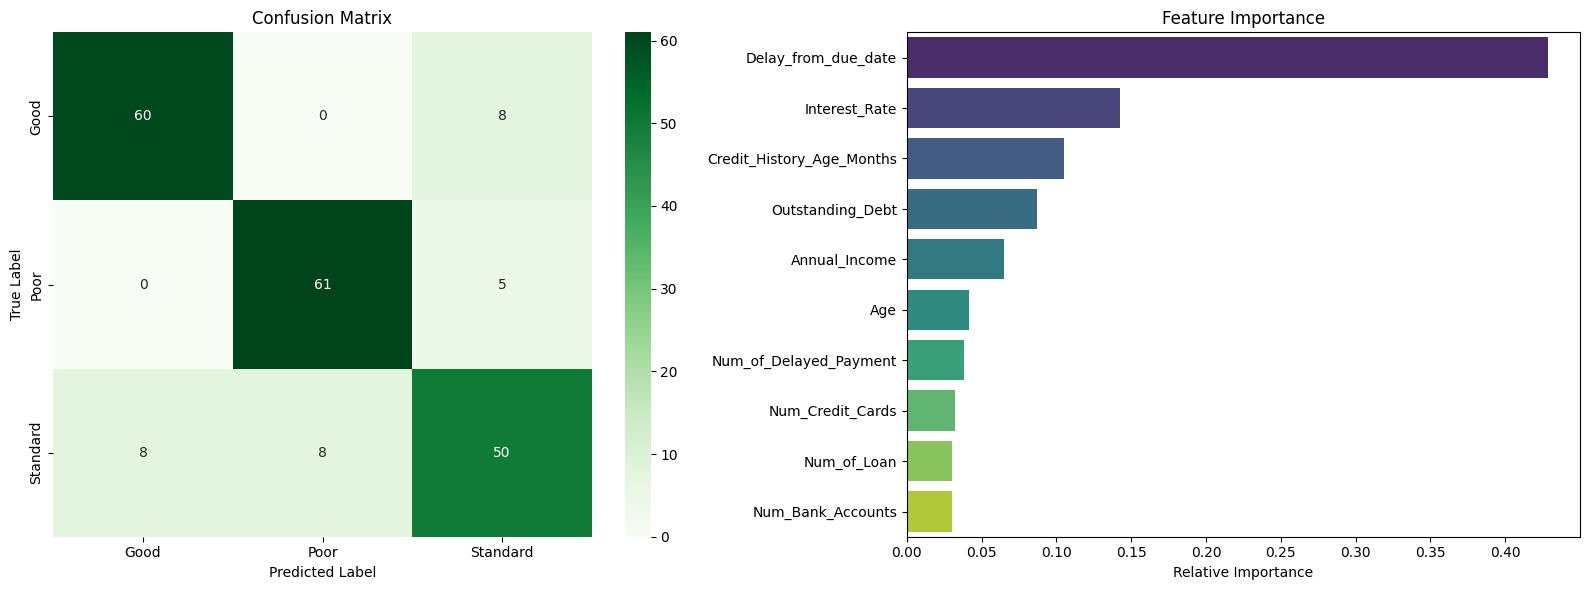

In [4]:
# 4. Model Evaluation and Presentable Report
accuracy = accuracy_score(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()

print("===================================================")
print(f"   CREDIT SCORE CLASSIFICATION MODEL REPORT        ")
print("===================================================")
print(f"Overall Model Accuracy: {accuracy * 100:.2f}%\n")

print("Detailed Metrics:")
display(report_df.style.background_gradient(cmap='Blues'))

# Plotting Confusion Matrix & Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[0])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Feature Importance Plot
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
feature_names = X.columns

sns.barplot(x=importances[indices], y=[feature_names[i] for i in indices], palette='viridis', ax=axes[1])
axes[1].set_title('Feature Importance')
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()
